# Train and inspect a cross-modal map

Train **T: RNA → ATAC** on paired gastrulation cells with the existing `coati.maps.train_map` function. This tutorial trains the map alone, then checks unseen paired cells by **cell type, observation stage and paired reconstruction**.

We reserve 20% of pairs within each stage as a test set before calling `train_map`. The remaining pairs are internally split into optimization and checkpoint-selection rows. Test pairs never select the map checkpoint, UMAP or label classifiers. All four stages remain represented: this is a **paired-cell holdout**, not a new-stage experiment.

COATI uses `celltype`, numeric `time`, matching `barcode`/`obs_names` and row-aligned embeddings. Source data: Argelaguet and colleagues, [GSE205117](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE205117). Use the prepared RNA50 / ATAC14 files from [TraInfBench](https://github.com/shankswang953/TraInfBench). Install `.[notebooks,visualization]` and set `DATA_DIR` to your local `gastrulation` folder.

In [1]:
from pathlib import Path
import os
import uuid
import json
import hashlib
import numpy as np
import pandas as pd
import torch
import anndata as ad
import joblib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
from umap import UMAP
import coati as ct
from coati.maps import train_map, load_map

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 11})
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = Path(os.environ.get("COATI_GASTRULATION_DATA", project_dir.parent / "TraInfBench/data/processed/gastrulation"))
output_dir = Path("outputs") / ("gastrulation-map-" + uuid.uuid4().hex[:8])
map_kind = "film"  # Choose "mlp" for a map without time conditioning.
map_config = ct.MapConfig(epochs=300, patience=30)


/Users/jingfeng/local/project/COATI/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Read and verify paired inputs

`X_latent` contains already-scaled RNA PCA50 / ATAC LSI14 features. Do not normalize them a second time. Paired barcodes and observation times must match before attaching ATAC to the prepared AnnData. Missing annotations remain `unknown`; they are shown in gray and excluded from cell-type accuracy calculations.

In [2]:
rna = ad.read_h5ad(DATA_DIR / "rna.h5ad")
atac = ad.read_h5ad(DATA_DIR / "atac.h5ad")
assert rna.obs_names.is_unique and rna.obs_names.equals(atac.obs_names)
np.testing.assert_array_equal(rna.obs["time_point_processed"], atac.obs["time_point_processed"])
assert rna.obsm["X_latent"].shape == (rna.n_obs, 50)
assert atac.obsm["X_latent"].shape == (atac.n_obs, 14)
cells = ct.prepare_anndata(
    rna, use_rep="X_latent", time_key="time_point_processed",
    celltype=rna.obs["celltype"].astype(object).fillna("unknown"),
    secondary=atac.obsm["X_latent"], secondary_key="X_atac", warn=False,
)
x, y = cells.obsm["X_latent"], cells.obsm["X_atac"]
times = cells.obs["time"].to_numpy()
stages = cells.obs["stage"].astype(str).to_numpy()
labels = cells.obs["celltype"].astype(str).to_numpy()
print("Paired cells:", cells.n_obs, "RNA:", x.shape, "ATAC:", y.shape)


Paired cells: 35503 RNA: (35503, 50) ATAC: (35503, 14)


## Reserve test pairs before fitting

Split RNA and ATAC together, preserving source row identities. The random split uses stage membership, not cell-type labels. Frozen source PCA/LSI and scalar preprocessing were prepared before this split, so this is not a raw-data preprocessing holdout.

In [3]:
rng = np.random.default_rng(17)
reference_parts, test_parts = [], []
for time in np.unique(times):
    rows = rng.permutation(np.flatnonzero(times == time))
    n_test = round(.2 * len(rows))
    test_parts.append(rows[:n_test])
    reference_parts.append(rows[n_test:])
reference_rows = np.sort(np.concatenate(reference_parts))
test_rows = np.sort(np.concatenate(test_parts))
assert not np.intersect1d(reference_rows, test_rows).size
assert len(reference_rows) + len(test_rows) == cells.n_obs
reference_cells = cells[reference_rows].copy()
paired = ct.TemporalData.from_anndata(reference_cells, secondary_obsm_key="X_atac")
print("Map fitting + validation:", len(reference_rows), "Independent test pairs:", len(test_rows))


Map fitting + validation: 28402 Independent test pairs: 7101


## Fit T independently

`train_map` fits, validates, saves and freezes the map; no vector field is trained here. Internal validation chooses the checkpoint and generates the existing paired-error and distribution reports. FiLM takes `(RNA, time)`; an MLP ignores time. Test cells are not passed to this function.

Its default quality thresholds are diagnostic screens. The separate test checks below assess cell-type and stage consistency rather than treating a passed validation report as biological proof.

In [4]:
output_dir.mkdir(parents=True, exist_ok=False)
T, map_report = train_map(
    paired, kind=map_kind, config=map_config,
    directory=output_dir / "map", device="cpu", seed=0,
)
print("Map:", map_kind, "Best epoch:", map_report["best_epoch"],
      "Epochs completed:", map_report["epochs_completed"], "Validation:", map_report["status"])
pd.DataFrame(map_report["stages"])[["time", "train_cells", "validation_cells", "normalized_mse", "sinkhorn_ratio"]]


Map: film Best epoch: 49 Epochs completed: 79 Validation: passed


,time,train_cells,validation_cells,normalized_mse,sinkhorn_ratio
0,0.0,5771,1443,0.199294,0.645887
1,1.0,4990,1247,0.107552,0.479868
2,2.0,7341,1835,0.100001,0.460511
3,2.5,4620,1155,0.107002,0.495861


## Predict unseen pairs and verify checkpoint reload

Run T on held-out RNA cells at their observed times. Recover optimization and validation IDs from the saved splits; only optimization rows will fit the ATAC UMAP and reference classifiers. Compare the reloaded map on exactly the same test pairs.

In [5]:
splits = np.load(output_dir / "map/splits.npz", allow_pickle=False)
fit_parts, validation_parts = [], []
for k, time in enumerate(paired.times):
    global_rows = reference_rows[times[reference_rows] == time]
    fit_parts.append(global_rows[splits[f"train_{k}"]])
    validation_parts.append(global_rows[splits[f"validation_{k}"]])
fit_rows = np.concatenate(fit_parts)
validation_rows = np.concatenate(validation_parts)
assert not np.intersect1d(fit_rows, validation_rows).size
assert not np.intersect1d(fit_rows, test_rows).size
assert not np.intersect1d(validation_rows, test_rows).size
assert set(np.concatenate([fit_rows, validation_rows, test_rows])) == set(range(cells.n_obs))

def map_points(model, points, query_times):
    with torch.no_grad():
        return np.concatenate([
            model(torch.tensor(points[i:i+1024]), torch.tensor(query_times[i:i+1024], dtype=torch.float32)).numpy()
            for i in range(0, len(points), 1024)
        ])

predicted = map_points(T, x[test_rows], times[test_rows])
restored = load_map(output_dir / "map/model.pt", device="cpu")
np.testing.assert_array_equal(predicted, map_points(restored, x[test_rows], times[test_rows]))
assert predicted.shape == y[test_rows].shape and np.isfinite(predicted).all()
print("Optimization / validation / test:", len(fit_rows), len(validation_rows), len(test_rows))
print("Exact map checkpoint reload: passed")


Optimization / validation / test: 22722 5680 7101
Exact map checkpoint reload: passed


## Compare in a shared ATAC UMAP

The RNA panel reuses the supplied source RNA UMAP. A new ATAC UMAP is fitted **only on real optimization ATAC cells**, then frozen. The real test ATAC and T outputs both use its `transform`; they never fit separate embeddings. Test truth labels color the mapped cells, making displaced or mixed groups visible.

RNA and ATAC axes describe different spaces. UMAP is a visualization, not the space in which the accuracy scores are calculated.

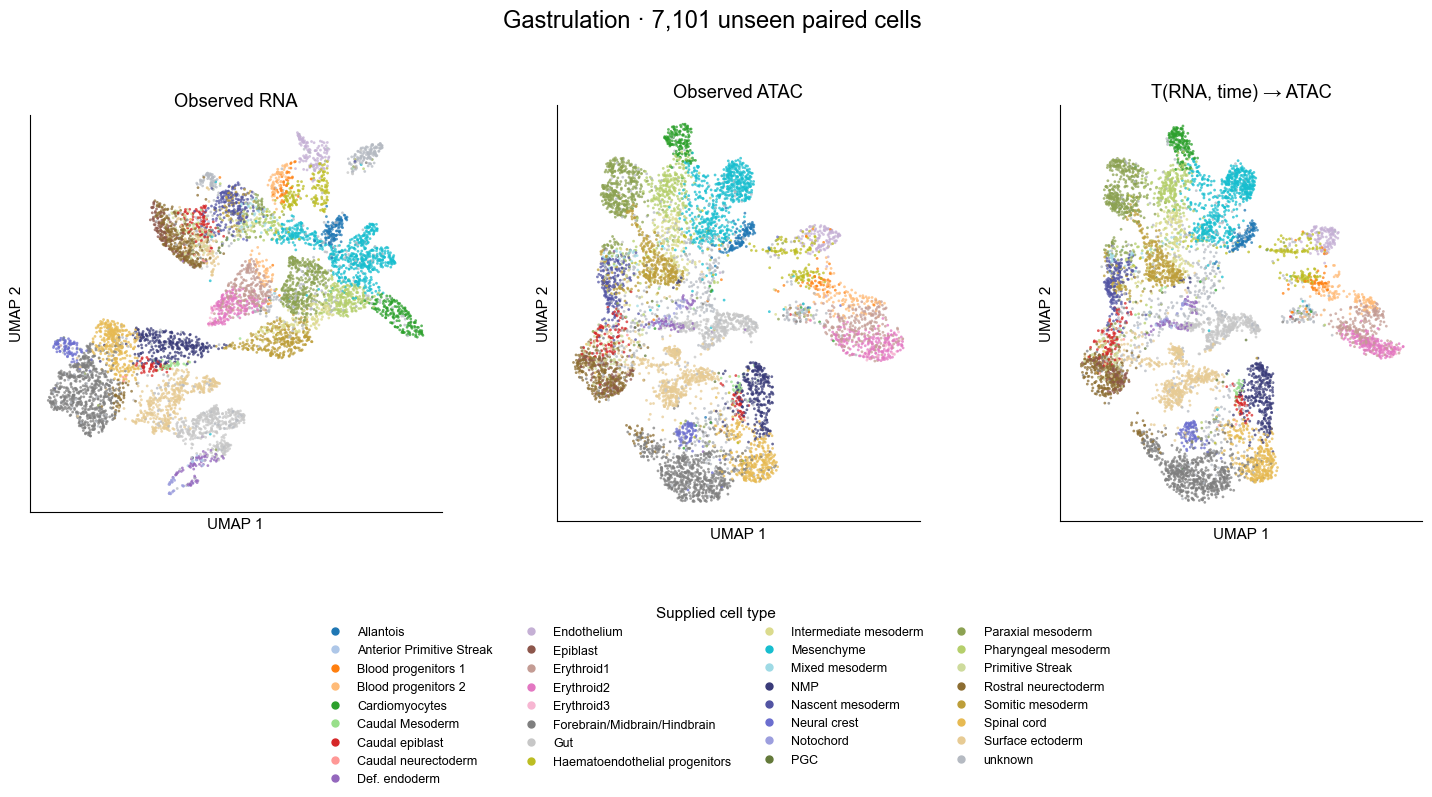

In [6]:
atac_umap = UMAP(n_neighbors=30, min_dist=.35, random_state=0, transform_seed=0, n_jobs=1)
atac_umap.fit(y[fit_rows])
real_atac_umap = atac_umap.transform(y[test_rows])
mapped_atac_umap = atac_umap.transform(predicted)
rna_umap = cells.obsm["X_umap"][test_rows]
joblib.dump(atac_umap, output_dir / "atac_reference_umap.joblib")
assert np.isfinite(real_atac_umap).all() and np.isfinite(mapped_atac_umap).all()

names = list(cells.obs["celltype"].cat.categories)
colors = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors)
palette = dict(zip(names, colors))
palette["unknown"] = "#b5bac2"
coordinates = [rna_umap, real_atac_umap, mapped_atac_umap]
titles = ["Observed RNA", "Observed ATAC", "T(RNA, time) → ATAC" if map_kind == "film" else "T(RNA) → ATAC"]
atac_limits = np.vstack([real_atac_umap, mapped_atac_umap])
low, high = atac_limits.min(0), atac_limits.max(0)
pad = .05 * np.maximum(high-low, 1.)

fig, axes = plt.subplots(1, 3, figsize=(15, 8))
for j, (ax, coords, title) in enumerate(zip(axes, coordinates, titles)):
    ax.scatter(*coords.T, c=[palette[label] for label in labels[test_rows]], s=4, alpha=.75, linewidths=0, rasterized=True)
    ax.set(title=title, xlabel="UMAP 1", ylabel="UMAP 2", xticks=[], yticks=[])
    ax.set_aspect("equal", adjustable="box")
    ax.spines[["top", "right"]].set_visible(False)
    if j > 0:
        ax.set(xlim=(low[0]-pad[0], high[0]+pad[0]), ylim=(low[1]-pad[1], high[1]+pad[1]))
shown_names = [name for name in names if name in set(labels[test_rows])]
handles = [Line2D([], [], marker="o", linestyle="", color=palette[name], label=name, markersize=5) for name in shown_names]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=9, title="Supplied cell type")
fig.suptitle(f"Gastrulation · {len(test_rows):,} unseen paired cells", fontsize=17, y=.98)
fig.subplots_adjust(left=.045, right=.99, bottom=.34, top=.86, wspace=.22)
fig.savefig(output_dir / "map_celltype_umap.png", dpi=180, bbox_inches="tight")
fig.savefig(output_dir / "map_celltype_umap.pdf", bbox_inches="tight")
plt.show()


## Check observation-stage structure

Use the same coordinates and cell order, now colored by the source stage. For FiLM, the supplied time conditions T; agreement therefore measures **preservation of stage structure given time**, not independent time inference. Stage mixing already present in real ATAC is part of the reference difficulty.

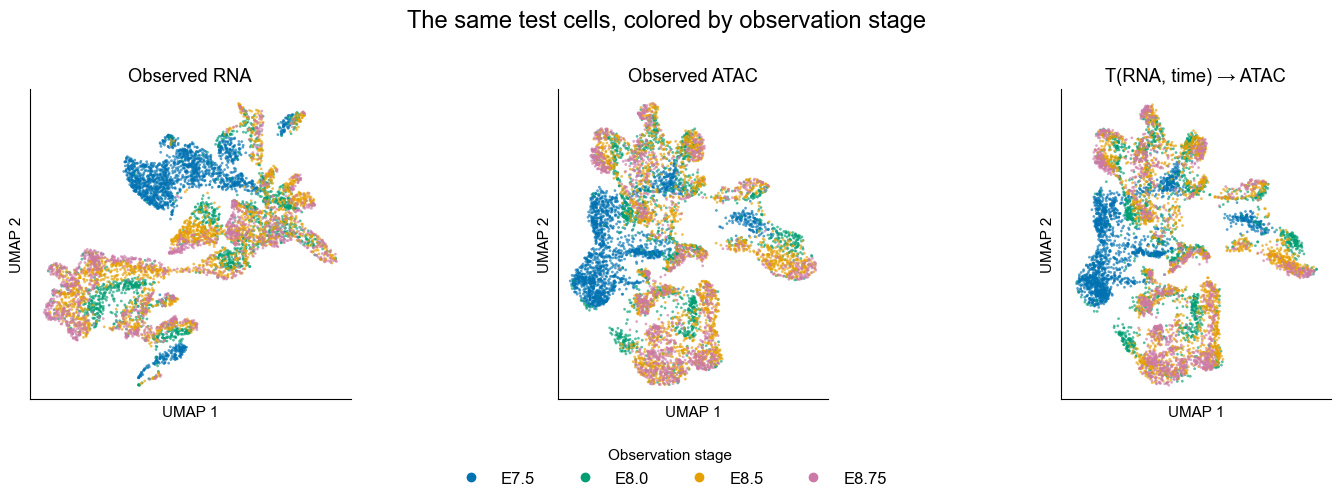

In [7]:
stage_order = [str(cells.obs.loc[cells.obs["time"] == t, "stage"].iloc[0]) for t in np.unique(times)]
stage_palette = dict(zip(stage_order, ["#0072b2", "#009e73", "#e69f00", "#cc79a7"]))
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for j, (ax, coords, title) in enumerate(zip(axes, coordinates, titles)):
    ax.scatter(*coords.T, c=[stage_palette[s] for s in stages[test_rows]], s=4, alpha=.65, linewidths=0, rasterized=True)
    ax.set(title=title, xlabel="UMAP 1", ylabel="UMAP 2", xticks=[], yticks=[])
    ax.set_aspect("equal", adjustable="box")
    ax.spines[["top", "right"]].set_visible(False)
    if j > 0:
        ax.set(xlim=(low[0]-pad[0], high[0]+pad[0]), ylim=(low[1]-pad[1], high[1]+pad[1]))
fig.legend(handles=[Line2D([], [], marker="o", linestyle="", color=stage_palette[s], label=s) for s in stage_order],
           loc="lower center", ncol=4, frameon=False, fontsize=12, title="Observation stage")
fig.suptitle("The same test cells, colored by observation stage", fontsize=17, y=.98)
fig.subplots_adjust(left=.045, right=.99, bottom=.20, top=.82, wspace=.22)
fig.savefig(output_dir / "map_time_umap.png", dpi=180, bbox_inches="tight")
fig.savefig(output_dir / "map_time_umap.pdf", bbox_inches="tight")
plt.show()


## Measure label agreement in ATAC14

Fit two distance-weighted 15-neighbor classifiers using only **real optimization ATAC cells**: one for supplied celltype, one for stage. Apply each frozen classifier to real test ATAC and mapped test ATAC. The real-ATAC result measures how well the annotations can be recovered with this same reference rule; it is a comparator, not a theoretical upper bound.

Unknown annotations are excluded from cell-type scores, but remain in plots and stage checks. Macro recall averages recall across the annotated types present in the test set, so common types do not dominate that score. These diagnostics do not change map training.

In [8]:
known_fit = fit_rows[labels[fit_rows] != "unknown"]
known_test = labels[test_rows] != "unknown"
celltype_reader = KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=1).fit(y[known_fit], labels[known_fit])
stage_reader = KNeighborsClassifier(n_neighbors=15, weights="distance", n_jobs=1).fit(y[fit_rows], stages[fit_rows])
real_types = celltype_reader.predict(y[test_rows])
mapped_types = celltype_reader.predict(predicted)
real_stages = stage_reader.predict(y[test_rows])
mapped_stages = stage_reader.predict(predicted)
scored_types = np.unique(labels[test_rows][known_test])
score_rows = []
for name, type_pred, stage_pred in [("Real test ATAC", real_types, real_stages), ("Mapped test ATAC", mapped_types, mapped_stages)]:
    score_rows.append({
        "Input": name, "Annotated cells": int(known_test.sum()),
        "Celltype agreement (%)": 100 * accuracy_score(labels[test_rows][known_test], type_pred[known_test]),
        "Celltype macro recall (%)": 100 * recall_score(labels[test_rows][known_test], type_pred[known_test], labels=scored_types, average="macro", zero_division=0),
        "Stage agreement (%)": 100 * accuracy_score(stages[test_rows], stage_pred),
    })
quality = pd.DataFrame(score_rows).set_index("Input")
quality.to_csv(output_dir / "label_agreement.csv")
quality.round(2)


,Annotated cells,Celltype agreement (%),Celltype macro recall (%),Stage agreement (%)
Input,,,,
Real test ATAC,6516,82.27,66.17,76.59
Mapped test ATAC,6516,83.81,67.42,80.23


## Locate stage-specific errors

Paired error compares each mapped test cell with its actual ATAC pair in ATAC14. Normalized MSE divides by the error of predicting the optimization-stage mean; one matches that baseline, lower is better. The stage confusion matrices show the same classifier's behavior on real and mapped ATAC.

,Test pairs,Annotated pairs,Paired RMSE,Normalized paired MSE,Real celltype (%),Mapped celltype (%),Real stage (%),Mapped stage (%)
Stage,,,,,,,,
E7.5,1804,1630,0.121,0.204,65.644,67.607,97.894,98.836
E8.0,1559,1441,0.130,0.110,85.913,87.647,66.389,68.377
E8.5,2294,2095,0.117,0.096,87.446,89.117,75.022,80.209
E8.75,1444,1350,0.112,0.109,90.444,91.037,63.504,69.806


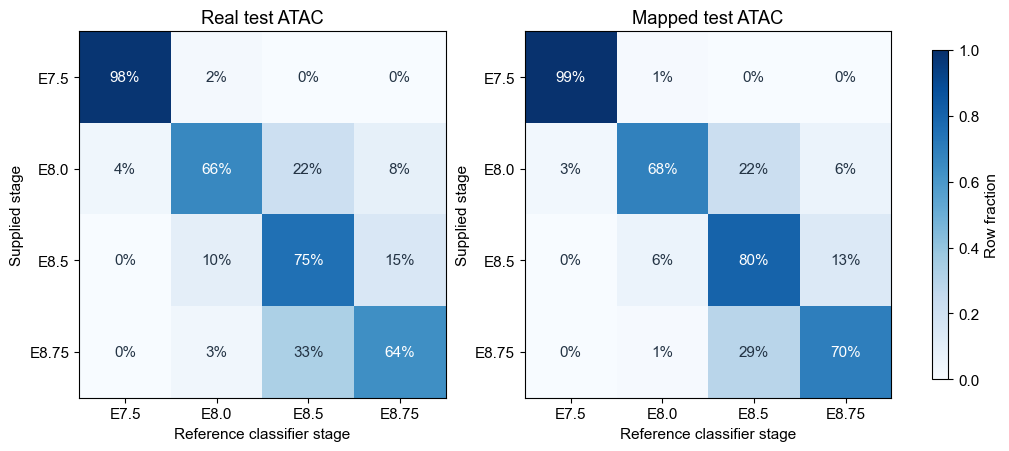

In [9]:
stage_rows = []
for stage in stage_order:
    mask = stages[test_rows] == stage
    truth, estimate = y[test_rows][mask], predicted[mask]
    baseline_mean = y[fit_rows][stages[fit_rows] == stage].mean(0)
    mse = float(np.mean((estimate-truth)**2))
    baseline_mse = float(np.mean((baseline_mean-truth)**2))
    known = mask & known_test
    stage_rows.append({"Stage": stage, "Test pairs": int(mask.sum()), "Annotated pairs": int(known.sum()),
        "Paired RMSE": float(np.sqrt(mse)), "Normalized paired MSE": mse / baseline_mse,
        "Real celltype (%)": 100 * accuracy_score(labels[test_rows][known], real_types[known]),
        "Mapped celltype (%)": 100 * accuracy_score(labels[test_rows][known], mapped_types[known]),
        "Real stage (%)": 100 * accuracy_score(stages[test_rows][mask], real_stages[mask]),
        "Mapped stage (%)": 100 * accuracy_score(stages[test_rows][mask], mapped_stages[mask])})
stage_quality = pd.DataFrame(stage_rows).set_index("Stage")
stage_quality.to_csv(output_dir / "stage_quality.csv")
display(stage_quality.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
for ax, predicted_stage, title in zip(axes, [real_stages, mapped_stages], ["Real test ATAC", "Mapped test ATAC"]):
    matrix = confusion_matrix(stages[test_rows], predicted_stage, labels=stage_order, normalize="true")
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{100*matrix[i,j]:.0f}%", ha="center", va="center", color="white" if matrix[i,j] > .5 else "#243445")
    ax.set(xticks=range(4), yticks=range(4), xticklabels=stage_order, yticklabels=stage_order,
           xlabel="Reference classifier stage", ylabel="Supplied stage", title=title)
fig.colorbar(image, ax=axes, shrink=.8, label="Row fraction")
fig.savefig(output_dir / "stage_confusion.png", dpi=180, bbox_inches="tight")
plt.show()


## Inspect cell types with lower agreement

Keep sample counts next to per-type recall: rare groups can have unstable scores. The table shows the ten lowest mapped recalls among types with at least 20 annotated test cells. All types, including smaller groups, remain included in the macro score and the saved CSV.

In [10]:
type_rows = []
for name in scored_types:
    mask = known_test & (labels[test_rows] == name)
    type_rows.append({"Cell type": name, "Test cells": int(mask.sum()),
                      "Real ATAC recall (%)": 100 * float(np.mean(real_types[mask] == name)),
                      "Mapped ATAC recall (%)": 100 * float(np.mean(mapped_types[mask] == name))})
type_quality = pd.DataFrame(type_rows).set_index("Cell type")
type_quality.to_csv(output_dir / "celltype_quality.csv")
type_quality[type_quality["Test cells"] >= 20].sort_values("Mapped ATAC recall (%)").head(10).round(2)


,Test cells,Real ATAC recall (%),Mapped ATAC recall (%)
Cell type,,,
Erythroid3,29,3.45,3.45
Mixed mesoderm,39,28.21,17.95
Primitive Streak,65,35.38,27.69
Epiblast,100,25.00,49.00
Blood progenitors 1,55,40.00,50.91
Caudal Mesoderm,33,45.45,51.52
Erythroid1,229,63.32,63.76
Intermediate mesoderm,168,69.05,66.07
Def. endoderm,76,67.11,67.11


## Save reproducible checks

Store model outputs, test barcodes, split roles, UMAP, classifiers and quality tables locally. The map reload check is exact. Dataset matrices and fitted artifacts are not committed to COATI.

A passed paired-MSE screen or a visually close UMAP does not establish that T is sufficiently accurate for every use. Compare mapped and real label agreement, inspect minority types and each stage, and relate the remaining errors to your downstream analysis. This test concerns unseen cells at observed stages, with source preprocessing kept fixed.

In [11]:
roles = np.full(cells.n_obs, "test", dtype="U12")
roles[fit_rows] = "optimization"
roles[validation_rows] = "validation"
pd.DataFrame({"barcode": cells.obs_names, "stage": stages, "role": roles}).to_csv(output_dir / "cell_splits.csv", index=False)
np.savez_compressed(output_dir / "test_predictions.npz", rna=x[test_rows], real_atac=y[test_rows], mapped_atac=predicted,
                    time=times[test_rows], celltype=labels[test_rows], barcode=cells.obs_names[test_rows].to_numpy(dtype=str),
                    test_rows=test_rows, real_umap=real_atac_umap, mapped_umap=mapped_atac_umap)
joblib.dump({"celltype": celltype_reader, "stage": stage_reader}, output_dir / "reference_classifiers.joblib")
report = {
    "dataset": "gastrulation", "accession": "GSE205117", "map_kind": map_kind,
    "seed": 0, "split_seed": 17, "input_dimensions": [50, 14],
    "source_sha256": {name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest() for name in ("rna.h5ad", "atac.h5ad")},
    "counts": {"optimization": len(fit_rows), "validation": len(validation_rows), "test": len(test_rows), "annotated_test": int(known_test.sum())},
    "map_config": map_config.to_dict(), "map_report": map_report,
    "quality": quality.reset_index().to_dict(orient="records"), "stage_quality": stage_quality.reset_index().to_dict(orient="records"),
    "celltype_quality": type_quality.reset_index().to_dict(orient="records"),
    "exact_map_reload": True, "disjoint_split_roles": True,
    "atac_umap_fit_rows": "optimization only", "atac_shared_transform": True,
    "classifier_reference": "real optimization ATAC14; 15 neighbors; distance weights",
    "time_is_map_input": map_kind == "film", "unknown_labels_excluded_from_celltype_scores": True,
    "scope": "Unseen paired cells within observed stages; precomputed source PCA/LSI and scales fixed. Stage consistency is conditional on supplied time for FiLM.",
}
(output_dir / "quality_report.json").write_text(json.dumps(report, indent=2) + "\n")
print("Saved:", output_dir.resolve())
print("Test pairs:", len(test_rows), "Annotated test pairs:", int(known_test.sum()))


Saved: /Users/jingfeng/local/project/COATI/outputs/gastrulation-map-8f309ee1
Test pairs: 7101 Annotated test pairs: 6516


## Read the result

In this executed FiLM run, 7,101 independent test pairs include 6,516 annotated cells. Cell-type agreement is **83.81%** for mapped ATAC versus **82.27%** for real test ATAC under the same reference classifier; macro recall is **67.42%** versus **66.17%**. Stage agreement is **80.23%** versus **76.59%**.

The map preserves much of the broad structure, but the average hides group-specific errors: E7.5 mapped cell-type agreement is **67.61%**, and some annotated types remain difficult. A slightly higher classifier score after mapping can reflect regression smoothing; it does not make predicted ATAC more biologically accurate than measured ATAC. Decide whether T is suitable using the stage/type tables and your downstream use, rather than UMAP appearance alone.

These values describe this saved one-seed run. If you change the map, data or split, use your newly computed tables instead. FiLM stage agreement remains conditional on the time supplied to T.